# Виявлення фейкових новин методами глибинного навчання з контролем витоку ознак

**Авторка:** Діана Гасюк, група ІПЗ-41<br>
**Дисципліна:** Глибинне навчання<br>
**Заклад:** Карпатський національний університет імені Василя Стефаника<br>
**Рік:** 2026

---

## Анотація

Досліджено, чи здатна глибока нейронна мережа розрізняти фейкові й достовірні новини за мовою тексту за умови вилучення технічних ознак джерела. Використано корпус Fake and Real News обсягом 44 898 статей. Аудит даних показав, що мітку класу майже повністю визначають службові ознаки: класифікатор лише за полем `subject` досягає F1 = 1,000, лише за маркером «(Reuters)» F1 = 0,996. Після вилучення таких ознак і дублікатів (38 822 статей) навчено лінійну базову модель і багатошаровий перцептрон з двома прихованими шарами. На відкладеній тестовій вибірці (5 824 статей) нейронна мережа досягла точності 0,9902 (95% ДІ [0,9878; 0,9928]), F1 = 0,9894 і ROC-AUC = 0,9996. Різниця загальної точності з базовою моделлю статистично не значуща (точний тест Мак-Немара, p = 0,076), проте повнота за класом «фейк» у мережі значуще вища (p = 0,008).

**Ключові слова:** фейкові новини; класифікація тексту; глибока нейронна мережа; витік ознак; тест Мак-Немара.

---

## Зміст

1. Вступ
2. Дані та методи
3. Результати
4. Обговорення
5. Висновки
6. Відтворюваність

## 1. Вступ

**Актуальність.** Неправдиві новини в соціальних мережах поширюються значно швидше і ширше за правдиві, тоді як ресурс ручної перевірки обмежений. Автоматична попередня класифікація дає змогу впорядкувати потік матеріалів для фактчекерів.

**Проблема.** Публічні корпуси фейкових новин часто містять ознаки, що вказують на джерело, а не на зміст. Модель, навчена на таких даних, демонструє високу точність, яка не переноситься на нові джерела.

**Мета роботи:** побудувати й оцінити класифікатор фейкових новин на основі глибокої нейронної мережі, навчений на даних, очищених від ознак джерела, та реалізувати прототип сервісу.

**Дослідницьке запитання.** Чи здатна глибока нейронна мережа розпізнати фейкову новину за мовою тексту, якщо вилучити з даних технічні ознаки джерела?

**Гіпотези.**
* **H1.** Після вилучення ознак джерела нейронна мережа досягає на тестовій вибірці F1 за класом «фейк» не нижче 0,95.
* **H2.** Повнота нейронної мережі за класом «фейк» статистично значуще (α = 0,05) перевищує повноту лінійної базової моделі.

**Завдання:**
1. провести розвідувальний аналіз і аудит витоку ознак;
2. розробити процедуру очищення та поділу даних;
3. навчити базову модель і глибоку нейронну мережу;
4. оцінити моделі на відкладеній вибірці та перевірити статистичну значущість різниці;
5. проаналізувати помилки та обмеження.

In [1]:
import sys, json, platform, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from scipy import stats

from src import config
from src.data import load_raw, prepare, split, clean_text

config.ensure_dirs()
np.random.seed(config.SEED)
sns.set_theme(style="whitegrid", palette=["#2E6B52", "#C0563B"])
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
pd.set_option("display.max_colwidth", 110)
NAMES = {0: "достовірна", 1: "фейкова"}
R = {}  # ключові результати, зберігаються в reports/results.json

## 2. Дані та методи

### 2.1 Набір даних

Використано відкритий корпус Fake and Real News Dataset з платформи Kaggle. Клас «достовірна» (`real`, 0) утворюють статті агенції Reuters; клас «фейкова» (`fake`, 1) утворюють статті з ресурсів, позначених організаціями з перевірки фактів як ненадійні. Мітку присвоєно за джерелом публікації, а не за перевіркою окремих тверджень; це обмеження враховано в розділі 4.

*Таблиця 1. Структура та розподіл класів вихідного корпусу*

In [2]:
df = load_raw()
R["N_TOTAL"], R["N_FAKE"], R["N_REAL"] = len(df), int(df.label.sum()), int((df.label == 0).sum())
print(f"Статей: {len(df)}; ознак: {df.shape[1] - 1} (title, text, subject, date)")
df["label"].map(NAMES).value_counts().rename("кількість").rename_axis("клас").to_frame()

Статей: 44898; ознак: 4 (title, text, subject, date)


,кількість
клас,
фейкова,23481
достовірна,21417


### 2.2 Розвідувальний аналіз

*Таблиця 2. Порожні заголовки, порожні тексти та повторювані тексти за класами*

In [3]:
quality = pd.DataFrame({
    "порожній заголовок": df["title"].eq("").groupby(df["label"]).sum(),
    "порожній текст": df["text"].str.strip().eq("").groupby(df["label"]).sum(),
    "текст повторюється": df.duplicated(subset="text", keep=False).groupby(df["label"]).sum(),
}).rename(index=NAMES).rename_axis("клас")
quality

,порожній заголовок,порожній текст,текст повторюється
клас,,,
достовірна,0,1,438
фейкова,0,630,10954


Повтори зосереджені переважно в класі «фейкова». Без дедуплікації до поділу ідентичні тексти потрапили б одночасно до навчальної і тестової вибірок, що завищило б оцінки якості.

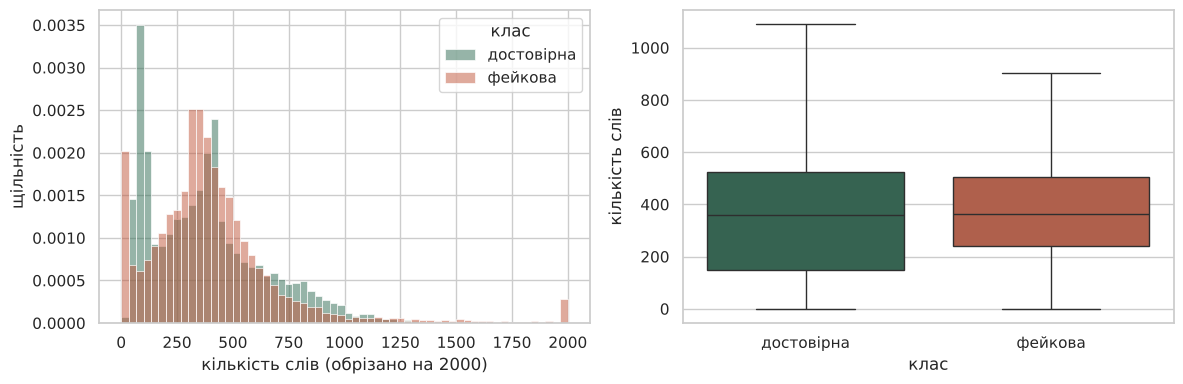

In [4]:
df["n_words"] = df["text"].str.split().str.len()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for lbl, name in NAMES.items():
    sns.histplot(df.loc[df.label == lbl, "n_words"].clip(upper=2000), bins=60, ax=axes[0],
                 label=name, stat="density", alpha=.5)
axes[0].set(xlabel="кількість слів (обрізано на 2000)", ylabel="щільність"); axes[0].legend(title="клас")
sns.boxplot(data=df.assign(клас=df.label.map(NAMES)), x="клас", y="n_words", hue="клас",
            order=["достовірна", "фейкова"], hue_order=["достовірна", "фейкова"], ax=axes[1], showfliers=False, legend=False)
axes[1].set(xlabel="клас", ylabel="кількість слів")
plt.tight_layout(); plt.show()

*Рисунок 1. Розподіл довжини статей за класами: гістограма (ліворуч) і діаграма розмаху без викидів (праворуч)*

*Таблиця 3. Описова статистика довжини статей, слів*

In [5]:
desc = df.groupby(df.label.map(NAMES).rename("клас"))["n_words"].describe().round(1)
desc.columns = ["n", "середнє", "ст. відхилення", "мінімум", "Q1", "медіана", "Q3", "максимум"]
R["MED_FAKE"], R["MED_REAL"] = float(desc.loc["фейкова", "медіана"]), float(desc.loc["достовірна", "медіана"])
desc.astype({"n": int})

,n,середнє,ст. відхилення,мінімум,Q1,медіана,Q3,максимум
клас,,,,,,,,
достовірна,21417,385.6,274.0,0.0,148.0,359.0,525.0,5172.0
фейкова,23481,423.2,408.4,0.0,240.0,363.0,506.0,8135.0


Тест Д'Агостіно-Пірсона: K² = 6495,5, p < 0,001
Тест Манна-Вітні (довжина, фейкові проти достовірних): p = 3,3e-13


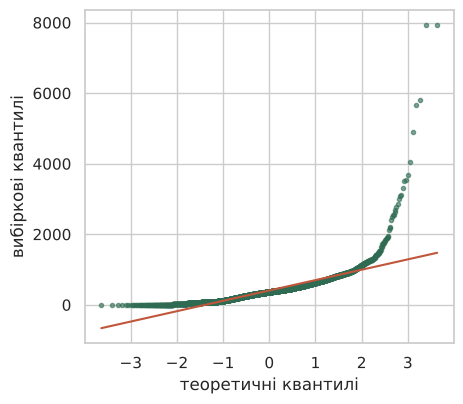

In [6]:
sample = df["n_words"].sample(5000, random_state=config.SEED)
k2, p_norm = stats.normaltest(sample)
_, p_mw = stats.mannwhitneyu(df.loc[df.label == 1, "n_words"], df.loc[df.label == 0, "n_words"])
R["K2"], R["P_NORM"], R["P_MW"] = float(k2), float(p_norm), float(p_mw)
print(f"Тест Д'Агостіно-Пірсона: K² = {k2:.1f}, p < 0,001".replace(".", ","))
print(f"Тест Манна-Вітні (довжина, фейкові проти достовірних): p = {p_mw:.1e}".replace(".", ","))

fig, ax = plt.subplots(figsize=(4.8, 4.2))
stats.probplot(sample, dist="norm", plot=ax)
ax.get_lines()[0].set(color="#2E6B52", markersize=3, alpha=.6); ax.get_lines()[1].set(color="#C0563B")
ax.set(title="", xlabel="теоретичні квантилі", ylabel="вибіркові квантилі")
plt.tight_layout(); plt.show()

*Рисунок 2. Квантиль-квантильний графік довжини статей відносно нормального розподілу (вибірка n = 5000)*

Розподіл довжини має виражену правосторонню асиметрію; гіпотезу нормальності відхилено тестом Д'Агостіно-Пірсона (K² = 6495,5, p < 0,001). Тому класи порівнювали непараметричним тестом Манна-Вітні: відмінність довжини статистично значуща (p = 3,3·10⁻¹³), однак медіани близькі (363 і 359 слів), тож довжина не є визначальною ознакою класу.

### 2.3 Аудит витоку ознак

Витоком ознак називають наявність у навчальних даних інформації, що корелює з міткою, але недоступна або нерелевантна в цільовому застосуванні. Перевірено три групи потенційних витоків: службове поле `subject`, датлайн агенції та підписи до ілюстрацій.

*Таблиця 4. Значення поля `subject` за класами*

In [7]:
pd.crosstab(df["subject"], df["label"].map(NAMES).rename("клас"))

клас,достовірна,фейкова
subject,,
Government News,0,1570
Middle-east,0,778
News,0,9050
US_News,0,783
left-news,0,4459
politics,0,6841
politicsNews,11272,0
worldnews,10145,0


*Таблиця 5. Частка статей зі службовими маркерами джерела, %*

In [8]:
markers = {"(Reuters)": r"\(reuters\)", "Getty Images": r"getty images",
           "Featured image": r"featured image", "pic.twitter.com": r"pic\.twitter\.com"}
leak = pd.DataFrame({name: df["text"].str.contains(rx, case=False, regex=True).groupby(df["label"]).mean()
                     for name, rx in markers.items()}).rename(index=NAMES).rename_axis("клас") * 100
R["REUTERS_REAL_PCT"], R["FEAT_FAKE_PCT"] = float(leak.loc["достовірна", "(Reuters)"]), float(leak.loc["фейкова", "Featured image"])
leak.round(1)

,(Reuters),Getty Images,Featured image,pic.twitter.com
клас,,,,
достовірна,99.2,0.0,0.0,0.0
фейкова,0.0,16.8,34.8,14.8


In [9]:
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline

y_all = df["label"]
f1_subject = cross_val_score(make_pipeline(OneHotEncoder(handle_unknown="ignore"), LogisticRegression(max_iter=1000)),
                             df[["subject"]], y_all, cv=5, scoring="f1").mean()
flag = df["text"].str.contains(r"\(reuters\)", case=False).astype(int).to_frame()
f1_reuters = cross_val_score(LogisticRegression(), flag, y_all, cv=5, scoring="f1").mean()
R["F1_SUBJECT"], R["F1_REUTERS"] = float(f1_subject), float(f1_reuters)
print(f"F1 (5-кратна крос-валідація), лише поле subject:      {f1_subject:.3f}".replace(".", ","))
print(f"F1 (5-кратна крос-валідація), лише маркер (Reuters):  {f1_reuters:.3f}".replace(".", ","))

F1 (5-кратна крос-валідація), лише поле subject:      1,000
F1 (5-кратна крос-валідація), лише маркер (Reuters):  0,996


Значення поля `subject` для двох класів не перетинаються (табл. 4), а маркер «(Reuters)» присутній у 99,2% достовірних статей і відсутній у фейкових (табл. 5). Класифікатори, що не мають доступу до змісту статті, досягають F1 = 1,000 і F1 = 0,996 відповідно. Отже, без очищення висока якість моделі свідчила б про розпізнавання джерела, а не ознак фейку (навчання за «коротким шляхом»).

### 2.4 Препроцесинг і поділ вибірки

Процедуру реалізовано у функції `src.data.clean_text`; вона однаково застосовується під час навчання й у прототипі. Кроки:
1. вилучення датлайну агенції («МІСТО (Reuters) -», «(Thomson Reuters Foundation)»), приміток про виправлення та службового вступу до публікацій твітів;
2. вилучення згадок «Reuters», підписів до ілюстрацій, посилань на зображення у Twitter;
3. приведення до нижнього регістру, вилучення URL, згадок користувачів, цифр і пунктуації;
4. вилучення токенів, виявлених аудитом характерних слів як ознаки джерела (код віджетів соцмереж, посилання на графіку Reuters, підписи фотобанків);
5. вилучення текстів коротших за 5 слів і дедуплікація **до** поділу;
6. стратифікований поділ 70 / 15 / 15 з фіксованим зерном.

Поля `subject` і `date` до ознак не включено.

In [10]:
example = df.loc[df.label == 0, "text"].iloc[0][:200]
print("До очищення:    ", example)
print("Після очищення: ", clean_text(example)[:200])

До очищення:     WASHINGTON (Reuters) - The head of a conservative Republican faction in the U.S. Congress, who voted this month for a huge expansion of the national debt to pay for tax cuts, called himself a “fiscal 
Після очищення:  the head of a conservative republican faction in the u s congress who voted this month for a huge expansion of the national debt to pay for tax cuts called himself a fiscal


*Таблиця 6. Обсяг і склад вибірок після очищення*

In [11]:
data = prepare(df)
train, val, test = split(data)
for name, part in (("train", train), ("val", val), ("test", test)):
    part.to_csv(config.PROCESSED_DIR / f"{name}.csv", index=False)
R.update(N_CLEAN=len(data), N_REMOVED=len(df) - len(data), N_TRAIN=len(train), N_VAL=len(val), N_TEST=len(test),
         FAKE_SHARE=float(train.label.mean()))
residual = int(data["clean"].str.contains(r"\breuters\b").sum()); R["RESIDUAL"] = residual
print(f"Вилучено дублікатів і коротких текстів: {len(df) - len(data)}; статей із залишковим 'reuters': {residual}")
pd.DataFrame({"статей": [len(train), len(val), len(test)],
              "частка фейкових": [train.label.mean(), val.label.mean(), test.label.mean()]},
             index=["навчальна", "валідаційна", "тестова"]).round(3)

Вилучено дублікатів і коротких текстів: 6076; статей із залишковим 'reuters': 2


,статей,частка фейкових
навчальна,27174,0.461
валідаційна,5824,0.461
тестова,5824,0.461


*Таблиця 7. Слова з найбільшим логарифмічним відношенням шансів між класами після очищення (навчальна вибірка)*

In [12]:
from sklearn.feature_extraction.text import CountVectorizer
cv = CountVectorizer(min_df=20, stop_words="english")
X = cv.fit_transform(train["clean"])
fake_c = np.asarray(X[train.label.values == 1].sum(0)).ravel() + 1
real_c = np.asarray(X[train.label.values == 0].sum(0)).ravel() + 1
log_odds = np.log(fake_c / fake_c.sum()) - np.log(real_c / real_c.sum())
top = pd.DataFrame({"слово": cv.get_feature_names_out(), "log-odds": log_odds}).sort_values("log-odds")
pd.concat([top.head(10).assign(клас="достовірна"), top.tail(10).assign(клас="фейкова")]).round(2).reset_index(drop=True)

,слово,log-odds,клас
0,hariri,-6.51,достовірна
1,rohingya,-6.47,достовірна
2,rakhine,-6.33,достовірна
3,puigdemont,-6.08,достовірна
4,zuma,-6.04,достовірна
5,myanmar,-5.86,достовірна
6,fdp,-5.80,достовірна
7,suu,-5.73,достовірна
8,kyi,-5.72,достовірна
9,mnangagwa,-5.62,достовірна


Після очищення для класу «достовірна» найхарактерніші власні назви міжнародної політики, для класу «фейкова» розмовна та оцінна лексика й теми внутрішньої політики США. Перша група свідчить про тематичний зсув корпусу, друга про стилістичні відмінності. Технічних ознак джерела серед найхарактерніших токенів не виявлено; слово «reuters» залишилося лише в 2 статтях, де воно є частиною змісту, а не службовою позначкою.

### 2.5 Моделі

**Базова модель:** TF-IDF за уні- і біграмами (50 000 ознак, сублінійне масштабування частот) і логістична регресія з L2-регуляризацією (C = 4).

**Основна модель:** багатошаровий перцептрон на ознаках TF-IDF.

*Таблиця 8. Конфігурація глибокої нейронної мережі*

| Параметр | Значення |
|---|---|
| Вхід | TF-IDF, 30 000 уні- і біграм, `min_df = 3` |
| Приховані шари | 256 і 64 нейрони, активація ReLU |
| Вихід | 1 нейрон, логістична функція |
| Оптимізатор | Adam, швидкість навчання 0,001 |
| Регуляризація | L2, α = 0,0001 |
| Розмір міні-батчу | 256 |
| Рання зупинка | за log-loss на валідаційній вибірці, терпіння 2 епохи |

Рекурентна архітектура BiLSTM реалізована в `src/models.py` як розширення і в цій роботі не оцінюється.

### 2.6 Протокол оцінювання

Тестова вибірка не використовувалася для навчання чи вибору гіперпараметрів. Позитивним класом є «фейкова». Метрики:

$$\text{Precision} = \frac{TP}{TP + FP}, \qquad \text{Recall} = \frac{TP}{TP + FN}, \qquad F_1 = \frac{2 \cdot \text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}},$$

а також accuracy і площа під ROC-кривою (ROC-AUC). Для порівняння моделей на тих самих об'єктах застосовано точний тест Мак-Немара; 95% довірчі інтервали отримано непараметричним бутстрепом (2 000 повторних вибірок). Рівень значущості α = 0,05.

## 3. Результати

### 3.1 Базова модель

*Таблиця 9. Якість базової моделі на валідаційній вибірці*

In [13]:
import joblib
from src.models import build_baseline
from src.evaluate import compute_metrics

baseline = build_baseline().fit(train["clean"], train["label"])
joblib.dump(baseline, config.BASELINE_PATH)
m = compute_metrics(val["label"].to_numpy(), baseline.predict_proba(val["clean"])[:, 1])
pd.DataFrame({"Accuracy": [m["accuracy"]], "Precision": [m["precision_fake"]], "Recall": [m["recall_fake"]],
              "F1": [m["f1_fake"]], "ROC-AUC": [m["roc_auc"]]}, index=["валідаційна вибірка"]).round(4)

,Accuracy,Precision,Recall,F1,ROC-AUC
валідаційна вибірка,0.9885,0.991,0.984,0.9875,0.999


### 3.2 Навчання глибокої нейронної мережі

In [14]:
from src.train import fit_dnn

dnn, history = fit_dnn(train, val, verbose=False)
joblib.dump(dnn, config.DNN_PATH)
mlp = dnn.named_steps["mlp"]
R["BEST_EPOCH"] = history["best_epoch"]
R["N_PARAMS"] = int(sum(w.size for w in mlp.coefs_) + sum(b.size for b in mlp.intercepts_))
print(f"Обрано епоху {history['best_epoch']}; параметрів: {R['N_PARAMS']:,}".replace(",", " "))

Обрано епоху 2; параметрів: 7 696 769


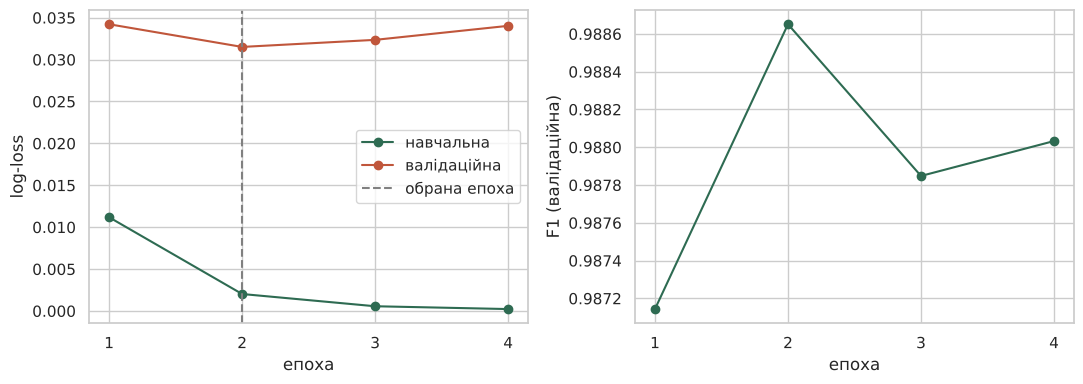

In [15]:
h = pd.DataFrame(history).drop(columns="best_epoch").set_index("epoch")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(h.index, h.train_loss, "o-", label="навчальна")
axes[0].plot(h.index, h.val_loss, "o-", label="валідаційна")
axes[0].axvline(history["best_epoch"], ls="--", color="grey", label="обрана епоха")
axes[0].set(xlabel="епоха", ylabel="log-loss"); axes[0].legend()
axes[1].plot(h.index, h.val_f1, "o-", color="#2E6B52")
axes[1].set(xlabel="епоха", ylabel="F1 (валідаційна)")
for ax in axes: ax.set_xticks(h.index)
plt.tight_layout(); plt.savefig(config.FIGURES_DIR / "dnn_learning_curves.png", dpi=150); plt.show()

*Рисунок 3. Криві навчання: log-loss на навчальній і валідаційній вибірках (ліворуч), F1 на валідаційній вибірці (праворуч)*

Втрати на навчальній вибірці монотонно спадають, а на валідаційній досягають мінімуму на епосі 2 і далі зростають, що свідчить про початок перенавчання. Збережено параметри епохи 2. Мережа містить 7 696 769 параметрів.

### 3.3 Якість на тестовій вибірці

*Таблиця 10. Метрики якості на тестовій вибірці (позитивний клас «фейкова»)*

In [16]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

y_test = test["label"].to_numpy()
scores = {"baseline": baseline.predict_proba(test["clean"])[:, 1], "dnn": dnn.predict_proba(test["clean"])[:, 1]}
metrics = {name: compute_metrics(y_test, p) for name, p in scores.items()}
with open(config.METRICS_PATH, "w") as f:
    json.dump(metrics, f, indent=2)
for key, name in (("B", "baseline"), ("D", "dnn")):
    m = metrics[name]
    R.update({f"ACC_{key}": m["accuracy"], f"PREC_{key}": m["precision_fake"], f"REC_{key}": m["recall_fake"],
              f"F1_{key}": m["f1_fake"], f"AUC_{key}": m["roc_auc"],
              f"FN_{key}": m["confusion_matrix"]["fn"], f"FP_{key}": m["confusion_matrix"]["fp"]})
table = pd.DataFrame(metrics).T.drop(columns=["confusion_matrix", "n_test"]).astype(float)
table.index = ["TF-IDF + логістична регресія", "Глибока нейронна мережа"]
table.columns = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
table.round(4)

,Accuracy,Precision,Recall,F1,ROC-AUC
TF-IDF + логістична регресія,0.9878,0.9891,0.9844,0.9867,0.9992
Глибока нейронна мережа,0.9902,0.9888,0.9899,0.9894,0.9996


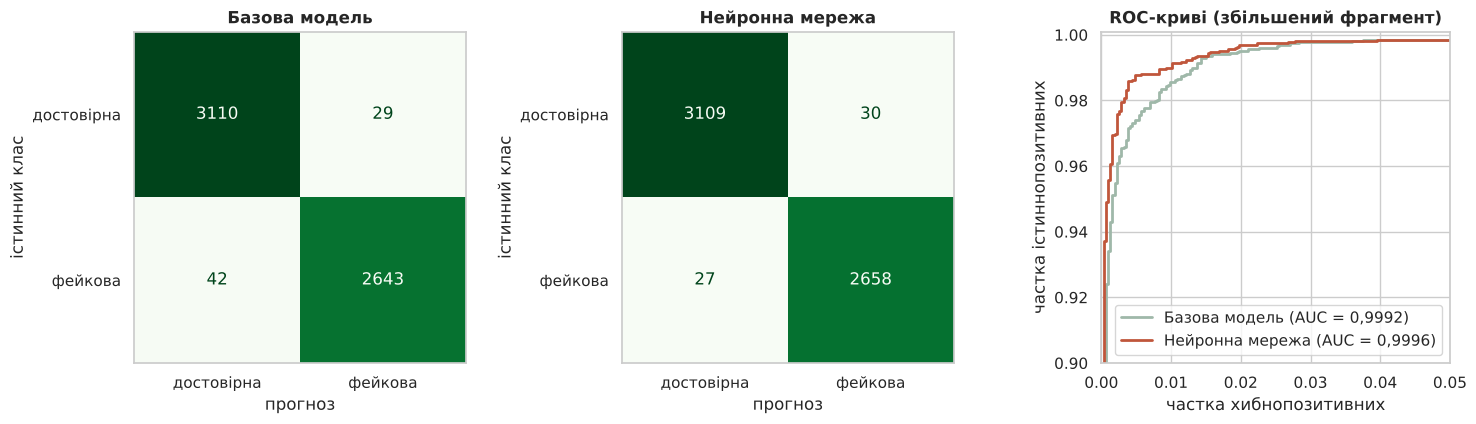

In [17]:
from sklearn.metrics import roc_curve
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
titles = {"baseline": "Базова модель", "dnn": "Нейронна мережа"}
for ax, (name, p) in zip(axes[:2], scores.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, (p >= .5).astype(int), display_labels=["достовірна", "фейкова"],
                                            cmap="Greens", colorbar=False, ax=ax)
    ax.grid(False)
    ax.set(title=titles[name], xlabel="прогноз", ylabel="істинний клас")
for (name, p), col in zip(scores.items(), ["#9FB8A9", "#C0563B"]):
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[2].plot(fpr, tpr, color=col, lw=2, label=f"{titles[name]} (AUC = {metrics[name]['roc_auc']:.4f})".replace(".", ","))
axes[2].set(xlim=(0, .05), ylim=(.9, 1.001), title="ROC-криві (збільшений фрагмент)",
            xlabel="частка хибнопозитивних", ylabel="частка істиннопозитивних")
axes[2].legend(loc="lower right")
plt.tight_layout(); plt.savefig(config.FIGURES_DIR / "test_evaluation.png", dpi=150); plt.show()

*Рисунок 4. Матриці помилок базової моделі та нейронної мережі (ліворуч) і ROC-криві на тестовій вибірці в діапазоні частки хибнопозитивних 0-0,05 (праворуч)*

Нейронна мережа досягла точності 0,9902, F1 = 0,9894 і ROC-AUC = 0,9996; базова модель відповідно 0,9878, 0,9867 і 0,9992. Мережа пропустила 27 фейкових статей проти 42 у базової моделі за 30 хибнопозитивних рішень проти 29.

### 3.4 Статистична значущість відмінностей

*Таблиця 11. Точний тест Мак-Немара для парних прогнозів*

In [18]:
from scipy.stats import binomtest
from sklearn.metrics import f1_score

pred = {k: (v >= .5).astype(int) for k, v in scores.items()}
ok_b, ok_d = pred["baseline"] == y_test, pred["dnn"] == y_test
rows = {}
for label, mask in (("усі статті (accuracy)", np.ones_like(y_test, bool)), ("фейкові статті (recall)", y_test == 1)):
    only_b, only_d = int((ok_b & ~ok_d & mask).sum()), int((~ok_b & ok_d & mask).sum())
    rows[label] = {"правильно лише базова": only_b, "правильно лише мережа": only_d,
                   "p": binomtest(min(only_b, only_d), only_b + only_d, .5).pvalue}
mc = pd.DataFrame(rows).T
R.update(MC_ALL_B=int(mc.iloc[0, 0]), MC_ALL_D=int(mc.iloc[0, 1]), MC_ALL_P=float(mc.iloc[0, 2]),
         MC_FAKE_B=int(mc.iloc[1, 0]), MC_FAKE_D=int(mc.iloc[1, 1]), MC_FAKE_P=float(mc.iloc[1, 2]))
mc.astype({"правильно лише базова": int, "правильно лише мережа": int}).round({"p": 4})

,правильно лише базова,правильно лише мережа,p
усі статті (accuracy),20,34,0.0759
фейкові статті (recall),7,22,0.0081


*Таблиця 12. 95% бутстреп-інтервали (2 000 повторних вибірок)*

In [19]:
rng = np.random.default_rng(config.SEED)
boot = {"accuracy мережі": [], "F1 мережі": [], "різниця accuracy (мережа мінус базова)": []}
for _ in range(2000):
    i = rng.integers(0, len(y_test), len(y_test))
    boot["accuracy мережі"].append(ok_d[i].mean())
    boot["F1 мережі"].append(f1_score(y_test[i], pred["dnn"][i]))
    boot["різниця accuracy (мережа мінус базова)"].append(ok_d[i].mean() - ok_b[i].mean())
ci = pd.DataFrame({k: np.percentile(v, [2.5, 97.5]) for k, v in boot.items()}, index=["нижня межа", "верхня межа"])
R["CI_ACC"] = ci["accuracy мережі"].tolist()
R["CI_F1"] = ci["F1 мережі"].tolist()
R["CI_DIFF"] = ci["різниця accuracy (мережа мінус базова)"].tolist()
ci.round(4)

,accuracy мережі,F1 мережі,різниця accuracy (мережа мінус базова)
нижня межа,0.9878,0.9867,-0.0002
верхня межа,0.9928,0.9921,0.0050


Різниця загальної точності статистично не значуща (p = 0,076; 95% ДІ різниці [-0,0002; 0,0050] містить нуль). Серед фейкових статей нейронна мережа правильно класифікувала 22 статей, хибно класифікованих базовою моделлю, при 7 зворотних випадках; ця різниця значуща (p = 0,008).

### 3.5 Зона невизначеності

У прототипі рішення з імовірністю в інтервалі [0,35; 0,65] передаються на ручну перевірку.

In [20]:
p = scores["dnn"]
confident = (p <= config.UNCERTAIN_LOW) | (p >= config.UNCERTAIN_HIGH)
R["CONF_SHARE"], R["CONF_ACC"] = float(confident.mean()), float(((p[confident] >= .5) == y_test[confident]).mean())
print(f"Частка впевнених рішень: {confident.mean():.2%}; точність на них: {R['CONF_ACC']:.2%}".replace(".", ","))

Частка впевнених рішень: 99,19%; точність на них: 99,45%


Упевнене рішення отримують 99,19% статей, точність на них становить 99,45%.

### 3.6 Аналіз помилок

*Таблиця 13. Десять помилок нейронної мережі з найвищою впевненістю*

In [21]:
err = test.assign(p_fake=scores["dnn"], pred=pred["dnn"])
wrong = err[err.pred != err.label].assign(впевненість=lambda d: (d.p_fake - .5).abs())
R["N_ERR"] = len(wrong)
print(f"Помилок: {len(wrong)} з {len(err)}")
(wrong.sort_values("впевненість", ascending=False)
      .head(10)[["label", "p_fake", "raw"]]
      .assign(label=lambda d: d.label.map(NAMES), raw=lambda d: d.raw.str[:100])
      .rename(columns={"label": "істинний клас", "p_fake": "P(фейк)", "raw": "початок тексту"})
      .round(3))

Помилок: 57 з 5824


,істинний клас,P(фейк),початок тексту
2280,достовірна,0.999,Highlights from Reuters' exclusive interview with Donald Trump. (Reuters) - Below are the highlights
4814,фейкова,0.005,"WOW! THE WASHINGTON POST Publishes #RealNews Story About President Trump : Under Trump’s Leadership,"
369,фейкова,0.017,OBAMA TAKES LEGALLY BINDING DRAFT TO UN SECURITY COUNCIL TO ENSURE NEXT PRESIDENT CAN’T UNDO IRAN NU
3432,достовірна,0.983,"Looming U.S. abortion ruling could be 'dangerous,' says top attorney. NEW YORK (Thomson Reuters Foun"
3054,достовірна,0.973,"Before the White House, Kennedy was a high-school prankster. BOSTON (Reuters) - Years before he capt"
3019,фейкова,0.032,BREAKING: Activist Appeals Court Rules Against Trump…Trump Comes Out Swinging…Tweets Awesome Reply.
4673,достовірна,0.965,Gorbachev sees Russian democracy far off: biographer Taubman. NEW YORK (Reuters) - Former Soviet lea
5783,фейкова,0.042,JAMES COMEY’S Bombshell Pre-Testimony Statement. Read former FBI Director James Comey s full stateme
2253,достовірна,0.953,"The Guardian's photographer of the year: Zohra Bensemra of Reuters. NEW YORK (Reuters) - In April, R"
5071,достовірна,0.919,"Trump, Cruz trade barbs over wives in presidential race. NEW YORK (Reuters) - Republican presidentia"


Найвпевненіші помилки належать до двох груп: достовірні матеріали нетипових жанрів (інтерв'ю, нариси, біографічні тексти), стилістично наближені до публіцистики, і фейкові тексти, що переказують або цитують публікації інших видань. Обидві групи відображають межу підходу: модель оцінює стиль, а не істинність тверджень.

### 3.7 Поведінка на текстах поза корпусом

Чотири тексти складено авторкою для якісної перевірки; результат не є статистичною оцінкою.

In [22]:
probe = [
    "The central bank kept its key interest rate unchanged on Thursday, citing slowing inflation, officials said.",
    "SHOCKING! Doctors HATE this one trick. The mainstream media will never tell you the truth about it!",
    "Lawmakers approved the budget bill by a vote of 52 to 48 after a lengthy debate in the Senate.",
    "You won't believe what this politician did. Share before it gets deleted!!!",
]
pd.DataFrame({"текст": [t[:70] for t in probe],
              "P(фейк), базова": baseline.predict_proba([clean_text(t) for t in probe])[:, 1],
              "P(фейк), мережа": dnn.predict_proba([clean_text(t) for t in probe])[:, 1]}).round(2)

,текст,"P(фейк), базова","P(фейк), мережа"
0,"The central bank kept its key interest rate unchanged on Thursday, cit",0.00,0.01
1,SHOCKING! Doctors HATE this one trick. The mainstream media will never,0.99,1.00
2,Lawmakers approved the budget bill by a vote of 52 to 48 after a lengt,0.14,0.05
3,You won't believe what this politician did. Share before it gets delet,0.97,0.99


Обидві моделі однаково ранжують тексти: стримані новинні формулювання отримують низьку ймовірність, сенсаційні з закликами до поширення високу.

## 4. Обговорення

**Перевірка гіпотез.** Гіпотезу H1 підтверджено: F1 нейронної мережі становить 0,9894 (95% ДІ [0,9867; 0,9921]), що перевищує поріг 0,95. Гіпотезу H2 підтверджено: повнота мережі значуще вища за повноту базової моделі (p = 0,008). Водночас загальна точність моделей статистично не відрізняється, тобто перевага мережі полягає у зміщенні балансу помилок на користь виявлення фейків.

**Значення аудиту даних.** Найвагоміший методологічний результат роботи полягає у виявленні та усуненні витоку ознак: без нього обидві моделі досягали б майже ідеальних метрик з іншої, хибної причини.

**Загрози валідності.**
* *Конструктна валідність.* Мітку присвоєно за джерелом, тому модель навчається відрізняти стиль джерел, а не встановлювати істинність тверджень.
* *Внутрішня валідність.* Тематичний зсув (міжнародна політика в класі «достовірна», внутрішня політика США в класі «фейкова») може частково пояснювати якість; повністю відокремити тему від стилю в межах цього корпусу неможливо.
* *Зовнішня валідність.* Корпус обмежений англомовними матеріалами 2015-2018 років; перенесення на інші мови, теми та періоди не перевірялося.

**Подальші дослідження:** оцінювання на незалежних корпусах (LIAR, FakeNewsNet), контроль теми через стратифікацію за рубриками, порівняння з рекурентними й трансформерними архітектурами, побудова україномовного корпусу на основі розмітки організацій з перевірки фактів.

## 5. Висновки

1. Аудит корпусу Fake and Real News виявив витік ознак: класифікатор лише за службовим полем досягає F1 = 1,000. Розроблена процедура очищення вилучає такі ознаки та повторювані тексти.
2. На очищених даних глибока нейронна мережа досягла на тестовій вибірці точності 0,9902, F1 = 0,9894 і ROC-AUC = 0,9996.
3. Порівняно з лінійною базовою моделлю мережа має статистично значуще вищу повноту за класом «фейк» (p = 0,008) при статистично незначущій різниці загальної точності (p = 0,076).
4. Отримана модель придатна для попереднього ранжування матеріалів для фактчекерів, але не для автоматичного встановлення істинності.

---

## 6. Відтворюваність

In [23]:
with open(config.REPORTS_DIR / "results.json", "w") as f:
    json.dump(R, f, indent=2, ensure_ascii=False)
print(f"Python {platform.python_version()} · numpy {np.__version__} · pandas {pd.__version__} · "
      f"scikit-learn {sklearn.__version__} · зерно {config.SEED}")

Python 3.13.18 · numpy 2.5.3 · pandas 3.0.5 · scikit-learn 1.9.1 · зерно 42


Усі обчислення детерміновані за фіксованого зерна. Ключові результати збережено в `reports/results.json`, метрики в `reports/metrics.json`, рисунки в `reports/figures/`.